Exploratory data analysis (Calfornia data) 

Author: Robin A.

In [ ]:
library(tidyverse)
library(skimr)

In [18]:
CA_fire = read_csv("CA_Fire_Data.csv")

Rows: 14988 Columns: 14
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (1): SEASON
dbl  (11): PRECIPITATION, MAX_TEMP, MIN_TEMP, AVG_WIND_SPEED, YEAR, TEMP_RAN...
lgl   (1): FIRE_START_DAY
date  (1): DATE

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [19]:
glimpse(CA_fire)

Rows: 14,988
Columns: 14
$ DATE                  <date> 1984-01-01, 1984-01-02, 1984-01-03, 1984-01-04,…
$ PRECIPITATION         <dbl> 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, …
$ MAX_TEMP              <dbl> 79, 71, 70, 76, 74, 65, 59, 59, 61, 70, 68, 69, …
$ MIN_TEMP              <dbl> 51, 46, 47, 45, 49, 49, 54, 55, 54, 47, 46, 47, …
$ AVG_WIND_SPEED        <dbl> 4.70, 5.59, 5.37, 4.70, 5.14, 7.38, 5.82, 3.36, …
$ FIRE_START_DAY        <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE,…
$ YEAR                  <dbl> 1984, 1984, 1984, 1984, 1984, 1984, 1984, 1984, …
$ TEMP_RANGE            <dbl> 28, 25, 23, 31, 25, 16, 5, 4, 7, 23, 22, 22, 14,…
$ WIND_TEMP_RATIO       <dbl> 0.05949367, 0.07873239, 0.07671429, 0.06184211, …
$ MONTH                 <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, …
$ SEASON                <chr> "Winter", "Winter", "Winter", "Winter", "Winter"…
$ LAGGED_PRECIPITATION  <dbl> 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, …
$ LAGGED_AVG_WI

In [22]:
CA_fire |>
  skim()

,skim_type,skim_variable,n_missing,complete_rate,Date.min,Date.max,Date.median,Date.n_unique,character.min,character.max,⋯,logical.mean,logical.count,numeric.mean,numeric.sd,numeric.p0,numeric.p25,numeric.p50,numeric.p75,numeric.p100,numeric.hist
,<chr>,<chr>,<int>,<dbl>,<date>,<date>,<date>,<int>,<int>,<int>,⋯,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,Date,DATE,0,1.0000000,1984-01-01,2025-01-12,2004-07-07,14988,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
2,character,SEASON,0,1.0000000,NA,NA,NA,NA,4,6,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
3,logical,FIRE_START_DAY,0,1.0000000,NA,NA,NA,NA,NA,NA,⋯,0.3316653,"FAL: 10017, TRU: 4971",NA,NA,NA,NA,NA,NA,NA,NA
4,numeric,PRECIPITATION,1,0.9999333,NA,NA,NA,NA,NA,NA,⋯,NA,NA,3.231467e-02,0.17954351,0.000000e+00,0.0000000,0.0000000,0.0000000,4.5300000,▇▁▁▁▁
5,numeric,MAX_TEMP,1,0.9999333,NA,NA,NA,NA,NA,NA,⋯,NA,NA,7.053500e+01,7.26344731,5.000000e+01,65.0000000,70.0000000,75.0000000,106.0000000,▂▇▅▁▁
6,numeric,MIN_TEMP,1,0.9999333,NA,NA,NA,NA,NA,NA,⋯,NA,NA,5.649409e+01,6.76768522,3.300000e+01,51.0000000,57.0000000,62.0000000,77.0000000,▁▃▇▇▁
7,numeric,AVG_WIND_SPEED,12,0.9991994,NA,NA,NA,NA,NA,NA,⋯,NA,NA,7.435098e+00,2.12998454,1.790000e+00,6.0400000,7.1600000,8.5000000,26.1700000,▅▇▁▁▁
8,numeric,YEAR,0,1.0000000,NA,NA,NA,NA,NA,NA,⋯,NA,NA,2.004017e+03,11.84334188,1.984000e+03,1994.0000000,2004.0000000,2014.0000000,2025.0000000,▇▇▇▇▇
9,numeric,TEMP_RANGE,1,0.9999333,NA,NA,NA,NA,NA,NA,⋯,NA,NA,1.404090e+01,5.99532675,2.000000e+00,10.0000000,12.0000000,17.0000000,41.0000000,▃▇▂▁▁


In [49]:
CA_fire |>
  group_by(FIRE_START_DAY) |>
  summarize(
    Avg_Max_Temp = mean(MAX_TEMP, na.rm = TRUE),
    Avg_Min_Temp = mean(MIN_TEMP, na.rm = TRUE),
    Avg_Wind_Speed = mean(AVG_WIND_SPEED, na.rm = TRUE),
    Avg_Precipitation = mean(PRECIPITATION, na.rm = TRUE),
    Avg_Temp_Range = mean(TEMP_RANGE, na.rm = TRUE),
    Total_Days = n()
  )

FIRE_START_DAY,Avg_Max_Temp,Avg_Min_Temp,Avg_Wind_Speed,Avg_Precipitation,Avg_Temp_Range,Total_Days
<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
FALSE,68.65036,54.26268,7.388233,0.046936901,14.38768,10017
TRUE,74.33233,60.99014,7.529423,0.002852545,13.34218,4971


In [53]:
CA_fire |>
  select(DATE, PRECIPITATION, MAX_TEMP, MIN_TEMP, AVG_WIND_SPEED, WIND_TEMP_RATIO) |>
  filter(is.na(PRECIPITATION) | is.na(MAX_TEMP) | is.na(MIN_TEMP) | is.na(AVG_WIND_SPEED)) |>
  arrange(DATE) |>
  print(n = 20)

# A tibble: 12 × 6
   DATE       PRECIPITATION MAX_TEMP MIN_TEMP AVG_WIND_SPEED WIND_TEMP_RATIO
   <date>             <dbl>    <dbl>    <dbl>          <dbl>           <dbl>
 1 1997-03-01             0       64       46             NA              NA
 2 1997-03-02             0       60       45             NA              NA
 3 1997-03-03             0       59       47             NA              NA
 4 2024-09-26             0       70       60             NA              NA
 5 2024-12-27             0       61       49             NA              NA
 6 2024-12-28             0       59       53             NA              NA
 7 2024-12-29             0       58       47             NA              NA
 8 2024-12-30             0       62       52             NA              NA
 9 2024-12-31            NA       NA       NA             NA              NA
10 2025-01-01             0       59       47             NA              NA
11 2025-01-11             0       66       46            

Warning message:
“Removed 15 rows containing non-finite outside the scale range (`stat_bin()`).”


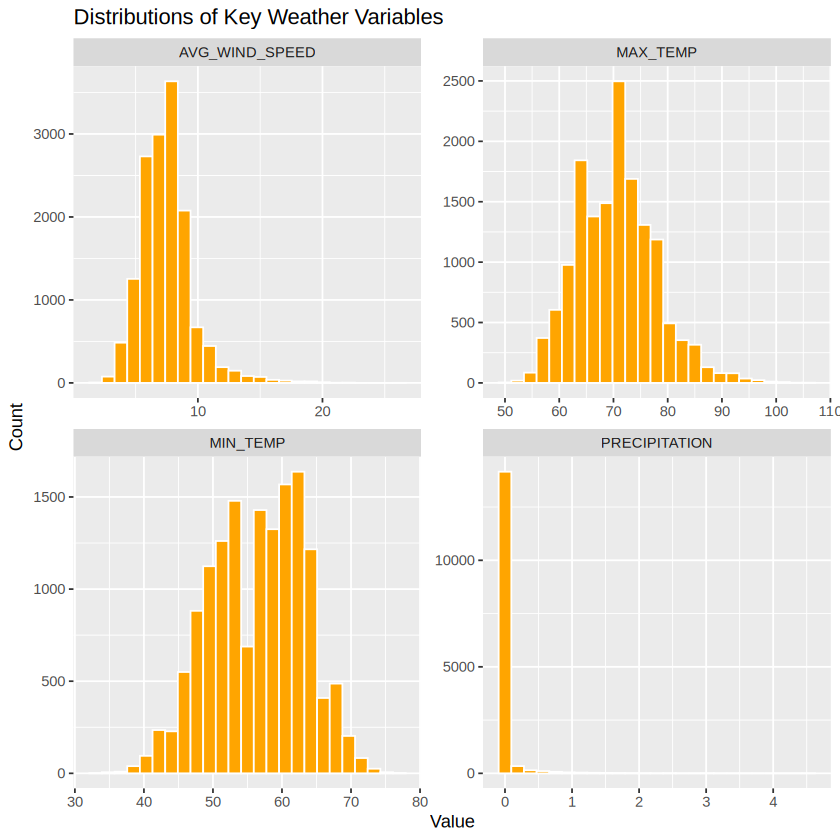

In [37]:
CA_fire |>
  select(MAX_TEMP, MIN_TEMP, AVG_WIND_SPEED, PRECIPITATION) |>
  pivot_longer(cols = everything(), names_to = "variable", values_to = "value") |>
  ggplot(aes(x = value)) +
  geom_histogram(bins = 25, fill = "orange", color = "white") +
  facet_wrap(~variable, scales = "free") +
  labs(title = "Distributions of Key Weather Variables",
       x = "Value",
       y = "Count")

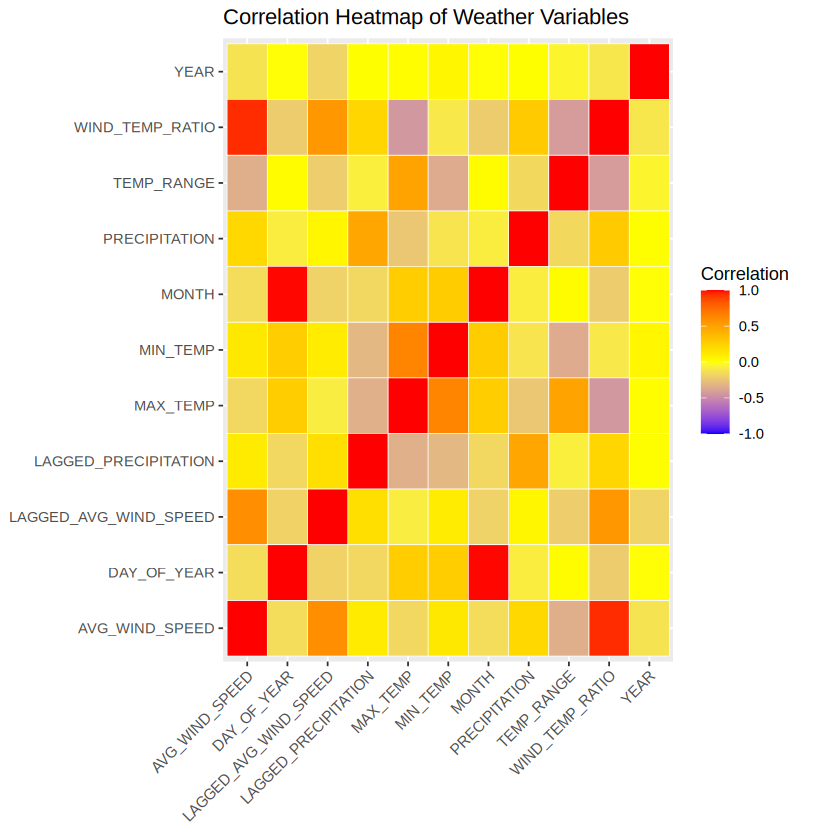

In [47]:
numeric_cols <- CA_fire |>
  select(where(is.numeric)) |>
  drop_na()

cor_matrix <- cor(numeric_cols)

cor_df <- as.data.frame(cor_matrix) |>
  rownames_to_column(var = "Var1") |>
  pivot_longer(-Var1, names_to = "Var2", values_to = "Correlation")

ggplot(cor_df, aes(x = Var1, y = Var2, fill = Correlation)) +
  geom_tile(color = "white") +
  scale_fill_gradient2(low = "blue", mid = "yellow", high = "red",
                       midpoint = 0, limit = c(-1, 1)) +
  theme(axis.text.x = element_text(angle = 45, vjust = 1, hjust = 1)) +
  labs(title = "Correlation Heatmap of Weather Variables", x = "", y = "")

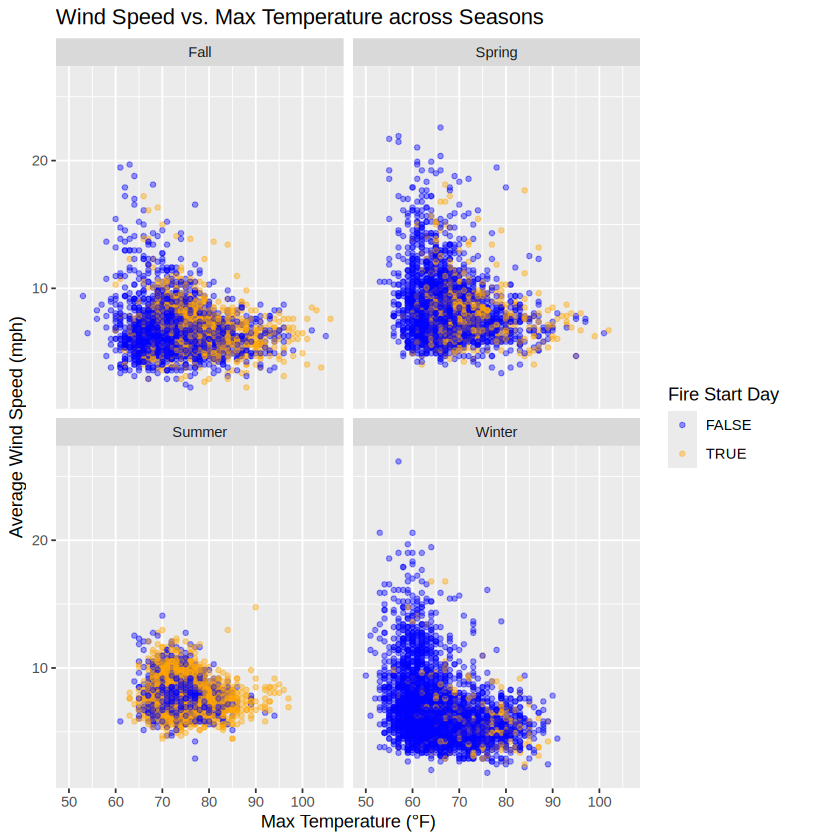

In [51]:
CA_fire |>
  filter(!is.na(MAX_TEMP) & !is.na(AVG_WIND_SPEED)) |>
  ggplot(aes(x = MAX_TEMP, y = AVG_WIND_SPEED, color = FIRE_START_DAY)) +
  geom_point(alpha = 0.4, size = 1.2) +
  facet_wrap(~SEASON) +
  scale_color_manual(values = c("FALSE" = "blue", "TRUE" = "orange")) +
  labs(
    title = "Wind Speed vs. Max Temperature across Seasons",
    x = "Max Temperature (°F)",
    y = "Average Wind Speed (mph)",
    color = "Fire Start Day"
  )

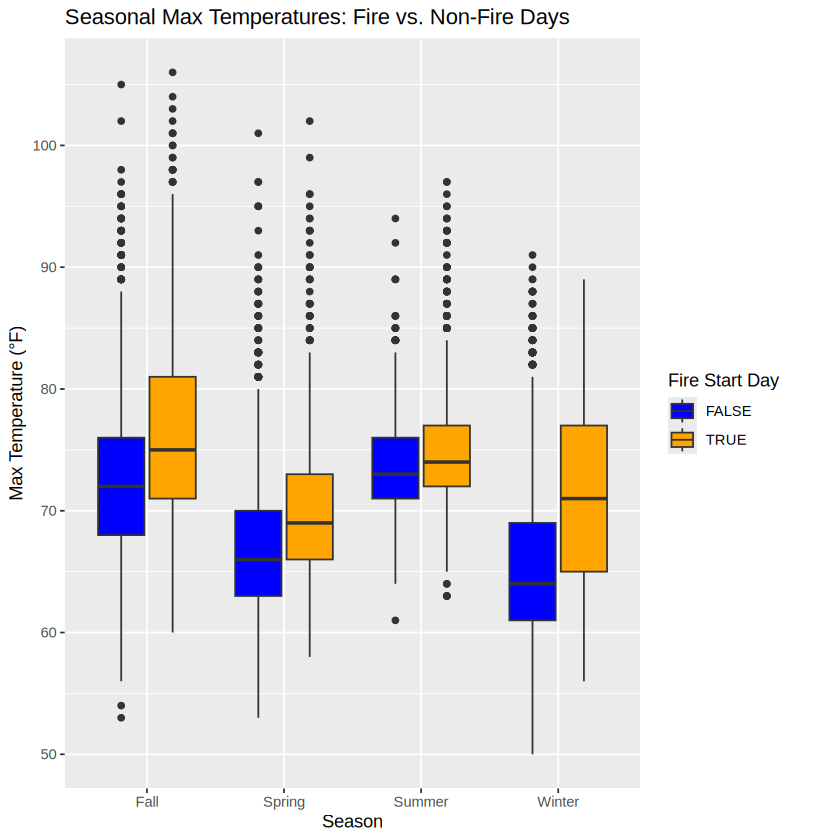

In [59]:
CA_fire |>
  filter(!is.na(MAX_TEMP)) |>
  ggplot(aes(x = SEASON, y = MAX_TEMP, fill = FIRE_START_DAY)) +
  geom_boxplot() +
  scale_fill_manual(values = c("FALSE" = "blue", "TRUE" = "orange")) +
  labs(
    title = "Seasonal Max Temperatures: Fire vs. Non-Fire Days",
    x = "Season",
    y = "Max Temperature (°F)",
    fill = "Fire Start Day"
  )

In [60]:
t_test_result <- t.test(MAX_TEMP ~ FIRE_START_DAY, data = CA_fire)

print(t_test_result)


	Welch Two Sample t-test

data:  MAX_TEMP by FIRE_START_DAY
t = -50.333, df = 10950, p-value < 2.2e-16
alternative hypothesis: true difference in means between group FALSE and group TRUE is not equal to 0
95 percent confidence interval:
 -5.903246 -5.460690
sample estimates:
mean in group FALSE  mean in group TRUE 
           68.65036            74.33233 

